# Popularity of archived books: does the description help? (with and without description, same books)

**Question.** Predict how often an archive.org book is viewed (existing *archived-item engagement*; **not** sales and **not** the success of an unpublished book), with
two versions of the inputs on exactly the same books, folds and final test set:

* **A – metadata only:** title words, creators, publication year, scanned pages, subject tags/genre flags, juvenile tag, archive age (from the two timestamps) and counts of creators/subjects.
* **B – metadata + description:** exactly the same inputs, plus the description text. Nothing else differs (`description_words` is *not* used).

**Tasks.** (1) classify low / medium / high views (tercile cut-offs fitted on training data only, separately inside each fold); (2) regression on `log1p(views_all_time)`, converted back to non-negative view estimates.
**Models in both variants:** dummy baselines, linear (LogisticRegression / Ridge), tree (HistGradientBoosting) and a small MLP (128-64, ReLU, AdamW) with group-aware early stopping.

**Rules followed.** One fixed split manifest saved *before* any model is fitted; grouping by `ol_group` (Open Library work) so copies of one work never straddle a split; a fresh holdout taken from new work groups that are absent from the earlier 5,600-book dataset;
all fitting (thresholds, scalers, TF-IDF, SVD, early stopping) uses training rows only; models are chosen with grouped cross-validation on the training pool and the choice is written to disk **before** the holdout is scored; the task is not changed to improve a score.

In [1]:
import json, time, warnings, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import popularity_experiment as pe
pe.OUT.mkdir(parents=True, exist_ok=True); FIG = pe.OUT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 60)
env = pe.environment(); (pe.OUT / "environment.json").write_text(json.dumps(env, indent=2), encoding="utf-8")
env

{'python': '3.13.2',
 'platform': 'Windows-11-10.0.26300-SP0',
 'numpy': '2.2.3',
 'pandas': '2.2.3',
 'scipy': '1.15.2',
 'scikit-learn': '1.6.1',
 'torch': '2.14.0+cpu',
 'joblib': '1.4.2',
 'torch_cuda_available': False,
 'device_used': 'cpu',
 'cpu_count': 16,
 'seed': 2026,
 'mlp_seeds': [2026, 2027, 2028],
 'n_folds': 5,
 'holdout_fraction': 0.17,
 'bootstrap_resamples': 1000,
 'mlp': {'hidden_layers': [128, 64],
  'activation': 'ReLU',
  'optimizer': 'AdamW',
  'lr': 0.001,
  'batch_size': 256,
  'max_epochs': 100,
  'patience': 10,
  'validation': '15% of training work groups'},
 'data_file': 'data\\popularity_training_clean.csv',
 'data_sha256': '52ba0b86e0c1a9484d4b4b42a16de9aced234a497dbf2a764a66ba99508d3c1e'}

## 1. The fixed dataset and the inputs

In [2]:
df = pe.load_cohort()
print("rows", len(df), "| distinct Open Library works (ol_group)", df.ol_group.nunique(), "| duplicate identifiers", int(df.identifier.duplicated().sum()))
print("missing values in required inputs:", int(df[["title","creators","subjects","description","publication_year","scanned_page_count","views","addeddate","retrieved_at_utc","ol_group"]].replace("", np.nan).isna().sum().sum()))
assert not any("view" in c for c in pe.NUM_COLS), "a view-derived column is in the inputs"
print("numeric inputs  :", pe.NUM_COLS)
print("text inputs (A) : title + subject tags (TF-IDF, 8,000 words max) and one-hot creators (seen at least twice in the training rows)")
print("text input added in B only: description (TF-IDF 1-2 grams, 20,000 max)")
print("never used as inputs: views, identifiers, source_batch, sampling_stratum, in_benchmark, in_americana, run/method/status fields, raw timestamps (only used to compute archive age)")
df[["publication_year","scanned_page_count","age_years","views","description_words"]].describe().round(1)

rows 17727 | distinct Open Library works (ol_group) 16666 | duplicate identifiers 0
missing values in required inputs: 0
numeric inputs  : ['publication_year', 'log_pages', 'age_years', 'n_creators', 'n_subjects', 'title_words', 'genre_science_fiction', 'genre_fantasy', 'genre_mystery_thriller', 'juvenile']
text inputs (A) : title + subject tags (TF-IDF, 8,000 words max) and one-hot creators (seen at least twice in the training rows)
text input added in B only: description (TF-IDF 1-2 grams, 20,000 max)
never used as inputs: views, identifiers, source_batch, sampling_stratum, in_benchmark, in_americana, run/method/status fields, raw timestamps (only used to compute archive age)


,publication_year,scanned_page_count,age_years,views,description_words
count,17727.0,17727.0,17727.0,17727.0,17727.0
mean,2004.3,313.4,8.0,394.5,81.8
std,13.5,156.8,4.2,2061.1,68.3
min,1840.0,50.0,0.1,2.0,25.0
25%,2000.0,198.0,5.0,56.0,38.0
50%,2008.0,310.0,6.2,112.0,56.0
75%,2013.0,394.0,11.2,287.0,103.0
max,2020.0,1352.0,20.5,184689.0,1044.0


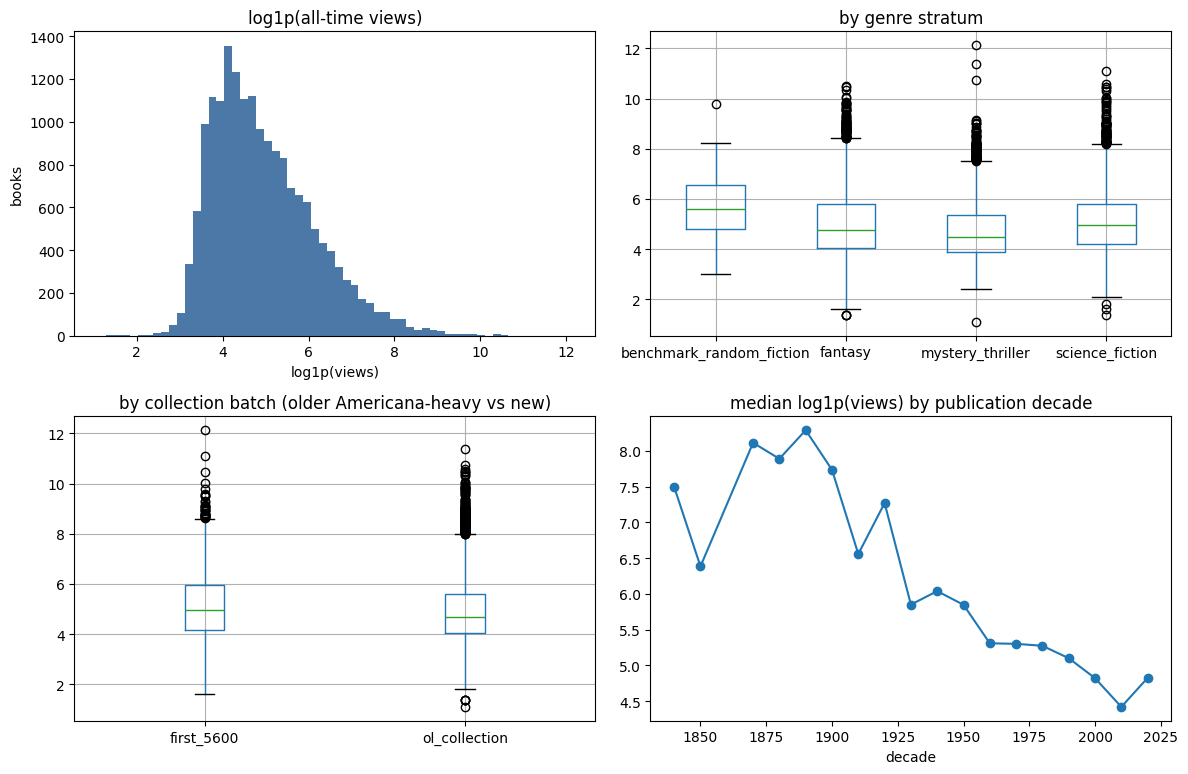

size  median   mean
genre stratum                          benchmark_random_fiction     52   270.5  873.1
                                       fantasy                    5989   118.0  458.1
                                       mystery_thriller           5875    88.0  286.5
                                       science_fiction            5811   139.0  434.0
source batch                           first_5600                 2826   140.5  553.7
                                       ol_collection             14901   108.0  364.4
in_americana (inspected, NOT an input) 0                         15880   101.0  343.0
                                       1                          1847   285.0  838.1

Spearman correlation of each numeric input with log views (EDA only):


,rho
publication_year,-0.253
log_pages,0.070
age_years,0.325
n_creators,0.189
n_subjects,-0.038
title_words,0.076
genre_science_fiction,0.105
genre_fantasy,0.072
genre_mystery_thriller,-0.144
juvenile,-0.052


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0,0].hist(df.log_views, bins=60, color="#4c78a8"); ax[0,0].set(title="log1p(all-time views)", xlabel="log1p(views)", ylabel="books")
df.boxplot(column="log_views", by="sampling_stratum", ax=ax[0,1]); ax[0,1].set(title="by genre stratum", xlabel="")
df.boxplot(column="log_views", by="source_batch", ax=ax[1,0]); ax[1,0].set(title="by collection batch (older Americana-heavy vs new)", xlabel="")
dec = (df.publication_year // 10) * 10
df.groupby(dec).log_views.median().plot(ax=ax[1,1], marker="o"); ax[1,1].set(title="median log1p(views) by publication decade", xlabel="decade")
plt.suptitle(""); plt.tight_layout(); plt.savefig(FIG / "eda_views.png", dpi=130); plt.show()
eda = pd.concat({"genre stratum": df.groupby("sampling_stratum").views.agg(["size","median","mean"]),
                 "source batch": df.groupby("source_batch").views.agg(["size","median","mean"]),
                 "in_americana (inspected, NOT an input)": df.groupby("in_americana").views.agg(["size","median","mean"])})
display(eda.round(1))
sp = df[pe.NUM_COLS + ["log_views"]].corr(method="spearman")["log_views"].drop("log_views").round(3)
print("Spearman correlation of each numeric input with log views (EDA only):"); display(sp.to_frame("rho"))

## 2. Split manifest (written before any model is fitted)

In [4]:
manifest = pe.build_split(df, force=True)
meta = {"seed": pe.SEED, "holdout_fraction_target": pe.HOLDOUT_FRACTION, "cv_folds": pe.N_FOLDS, "group_column": "ol_group",
        "holdout_rule": "whole ol_group units whose Open Library work id is absent from data/openlibrary_ids_5600.csv, same share per genre",
        "cv_stratification": "genre stratum + collection batch, grouped by ol_group",
        "manifest_sha256": pe.sha256_file(pe.OUT / "split_manifest.csv"), "created_utc": pd.Timestamp.utcnow().isoformat(),
        "rows_pool": int((manifest.split == "pool").sum()), "rows_holdout": int((manifest.split == "holdout").sum()),
        "groups_pool": int(manifest[manifest.split == "pool"].ol_group.nunique()), "groups_holdout": int(manifest[manifest.split == "holdout"].ol_group.nunique())}
(pe.OUT / "split_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print(json.dumps(meta, indent=2))
m = manifest.merge(df[["identifier","views"]], on="identifier")
display(m.groupby("split").agg(rows=("identifier","size"), groups=("ol_group","nunique"), median_views=("views","median"), new_batch_share=("source_batch", lambda s: (s=="ol_collection").mean())).round(3))
display(pd.crosstab(m.split, m.sampling_stratum))
display(pd.crosstab(m[m.split=="pool"].cv_fold, m[m.split=="pool"].sampling_stratum))
old_ids = set(pd.read_csv(pe.OL_IDS_FILE, encoding="utf-8-sig").openlibrary_work.dropna())
assert not (set(manifest[manifest.split=="holdout"].ol_group) & old_ids) and not (set(manifest[manifest.split=="holdout"].ol_group) & set(manifest[manifest.split=="pool"].ol_group))
print("checks passed: no group on both sides; no holdout group appears in the earlier 5,600-book dataset; each group is in one CV fold")

{
  "seed": 2026,
  "holdout_fraction_target": 0.17,
  "cv_folds": 5,
  "group_column": "ol_group",
  "holdout_rule": "whole ol_group units whose Open Library work id is absent from data/openlibrary_ids_5600.csv, same share per genre",
  "cv_stratification": "genre stratum + collection batch, grouped by ol_group",
  "manifest_sha256": "6a610d3f9a5bc4e494ea888e6bc5522f9499c486872b3ac0df4c78ce2c2bc2b1",
  "created_utc": "2026-11-22T17:29:10.311959+00:00",
  "rows_pool": 14721,
  "rows_holdout": 3006,
  "groups_pool": 13780,
  "groups_holdout": 2886
}


,rows,groups,median_views,new_batch_share
split,,,,
holdout,3006,2886,104.5,1.000
pool,14721,13780,114.0,0.808


sampling_stratum,benchmark_random_fiction,fantasy,mystery_thriller,science_fiction
split,,,,
holdout,0,1013,999,994
pool,52,4976,4876,4817


sampling_stratum,benchmark_random_fiction,fantasy,mystery_thriller,science_fiction
cv_fold,,,,
0,9,994,974,969
1,12,993,996,950
2,14,1000,963,974
3,8,1011,971,940
4,9,978,972,984


checks passed: no group on both sides; no holdout group appears in the earlier 5,600-book dataset; each group is in one CV fold


The holdout is drawn only from newly collected works, so it is **not** identically distributed with the training pool (new items have lower views, see the median above). This is deliberate (fresh, never-inspected items) but it means CV scores and holdout scores need not agree.

## 3. Grouped cross-validation on the training pool (identical folds, models and tuning budget for A and B)

In [5]:
t0 = time.time()
cv = pe.run_cv(df, manifest, n_jobs=5, force=True)
print("cross-validation finished in %.0f s" % (time.time() - t0))
res = cv["results"]; res.round(5).to_csv(pe.OUT / "cv_results_all_folds.csv", index=False)
fi = pd.DataFrame(cv["fold_info"]).sort_values("fold"); display(fi)
summary = pe.summarise_cv(res); summary.round(5).to_csv(pe.OUT / "cv_summary.csv", index=False)

cross-validation finished in 259 s


,fold,cuts,train_rows,val_rows,n_meta_features,n_desc_features,train_class_counts
0,0,"[71.0, 204.0]",11775,2946,6448,16181,"[3966, 3885, 3924]"
1,1,"[70.0, 205.0]",11770,2951,6379,16032,"[3939, 3920, 3911]"
2,2,"[70.0, 205.0]",11770,2951,6366,15956,"[3958, 3901, 3911]"
3,3,"[70.0, 205.0]",11791,2930,6479,16113,"[3945, 3923, 3923]"
4,4,"[70.0, 205.0]",11778,2943,6499,16053,"[3927, 3934, 3917]"


In [6]:
c = summary[summary.task == "classification"].copy()
c["setting"] = c.algo + " " + c.cfg_id.astype(str)
tab = c.pivot(index="setting", columns="variant", values=["accuracy", "macro_f1"]).round(4)
print("Classification, mean over 5 grouped folds (config ids: see cv_summary.csv)"); display(tab)
r = summary[summary.task == "regression"].copy(); r["setting"] = r.algo + " " + r.cfg_id.astype(str)
print("Regression, mean over 5 grouped folds"); display(r.pivot(index="setting", columns="variant", values=["r2_log", "median_ae_views", "within_2x"]).round(4))

Classification, mean over 5 grouped folds (config ids: see cv_summary.csv)


accuracy         macro_f1        
variant         A       B        A       B
setting                                   
dummy 0    0.3341  0.3341   0.1670  0.1670
hgb 0      0.5523  0.5571   0.5412  0.5458
hgb 1      0.5546  0.5642   0.5455  0.5549
hgb 2      0.5572  0.5645   0.5501  0.5574
logreg 0   0.5546  0.5713   0.5382  0.5561
logreg 1   0.5713  0.5821   0.5607  0.5725
logreg 2   0.5705  0.5791   0.5638  0.5732
logreg 3   0.5585  0.5682   0.5543  0.5645
mlp 0      0.5493  0.5527   0.5386  0.5399
mlp 1      0.5498  0.5569   0.5413  0.5447
mlp 2      0.5515  0.5553   0.5431  0.5423

Regression, mean over 5 grouped folds


r2_log         median_ae_views          within_2x        
variant              A       B               A        B         A       B
setting                                                                  
dummy_mean 0   -0.0001 -0.0001         92.5496  92.5496    0.4107  0.4107
dummy_median 0 -0.0343 -0.0343         71.8000  71.8000    0.4451  0.4451
hgb 0           0.2936  0.3090         67.4641  67.5230    0.5397  0.5432
hgb 1           0.3198  0.3319         65.6809  65.2488    0.5555  0.5657
hgb 2           0.3331  0.3430         65.1322  65.3621    0.5703  0.5761
mlp 0           0.3181  0.3426         66.3199  65.7121    0.5696  0.5812
mlp 1           0.3229  0.3454         65.3808  64.5655    0.5673  0.5803
mlp 2           0.3184  0.3450         66.1392  62.8005    0.5636  0.5771
ridge 0         0.3372  0.2924         66.4367  72.0847    0.5805  0.5525
ridge 1         0.3942  0.3894         63.3135  65.3411    0.5981  0.5896
ridge 2         0.4006  0.4187         62.7567  62.7866    0.5971  0.6031
ridge 3         0.3645  0.3947         64.9727  63.4617    0.5732  0.5878

### Model choice from cross-validation only
For each variant and task the best configuration of every algorithm is picked by CV macro-F1 (classification) or CV R² on log views (regression); the overall winner and the best non-neural model follow from the same CV numbers. The selection is written to disk now, **before the holdout is touched**.

In [7]:
selection = pe.select_models(summary)
selection.round(5).to_csv(pe.OUT / "cv_selection.csv", index=False)
(pe.OUT / "cv_selection_written_utc.txt").write_text(pd.Timestamp.utcnow().isoformat())
display(selection.sort_values(["task", "variant", "cv_value"], ascending=[True, True, False]))

,variant,task,algo,cfg_id,cfg,family,cv_criterion,cv_value,is_variant_winner,is_best_non_neural
2,A,classification,logreg,2,"{""C"": 1.0}",linear,macro_f1,0.563755,True,True
1,A,classification,hgb,2,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",tree,macro_f1,0.550114,False,False
3,A,classification,mlp,2,"{""weight_decay"": 0.1, ""dropout"": 0.5}",neural,macro_f1,0.543135,False,False
0,A,classification,dummy,0,{},baseline,macro_f1,0.166959,False,False
11,B,classification,logreg,2,"{""C"": 1.0}",linear,macro_f1,0.573151,True,True
10,B,classification,hgb,2,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",tree,macro_f1,0.557370,False,False
12,B,classification,mlp,1,"{""weight_decay"": 0.01, ""dropout"": 0.3}",neural,macro_f1,0.544703,False,False
9,B,classification,dummy,0,{},baseline,macro_f1,0.166959,False,False
8,A,regression,ridge,2,"{""alpha"": 3.0}",linear,r2_log,0.400648,True,True
6,A,regression,hgb,2,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",tree,r2_log,0.333075,False,False


In [8]:
pcv = pe.paired_cv(res, selection); pcv.round(4).to_csv(pe.OUT / "cv_paired_A_vs_B.csv", index=False)
print("Description effect inside CV: B minus A for the same algorithm on the same five folds"); display(pcv.round(4))

Description effect inside CV: B minus A for the same algorithm on the same five folds


,task,algo,metric,A_mean,B_mean,mean_B_minus_A,sd_of_fold_differences,folds_where_B_better,folds
0,classification,dummy,accuracy,0.3341,0.3341,0.0000,0.0000,0,5
1,classification,dummy,macro_f1,0.1670,0.1670,0.0000,0.0000,0,5
2,classification,logreg,accuracy,0.5705,0.5791,0.0086,0.0047,5,5
3,classification,logreg,macro_f1,0.5638,0.5732,0.0094,0.0046,5,5
4,classification,hgb,accuracy,0.5572,0.5645,0.0073,0.0068,4,5
5,classification,hgb,macro_f1,0.5501,0.5574,0.0073,0.0060,5,5
6,classification,mlp,accuracy,0.5515,0.5569,0.0054,0.0087,4,5
7,classification,mlp,macro_f1,0.5431,0.5447,0.0016,0.0104,4,5
8,regression,dummy_mean,r2_log,-0.0001,-0.0001,0.0000,0.0000,0,5
9,regression,dummy_mean,median_ae_views,92.5496,92.5496,0.0000,0.0000,0,5


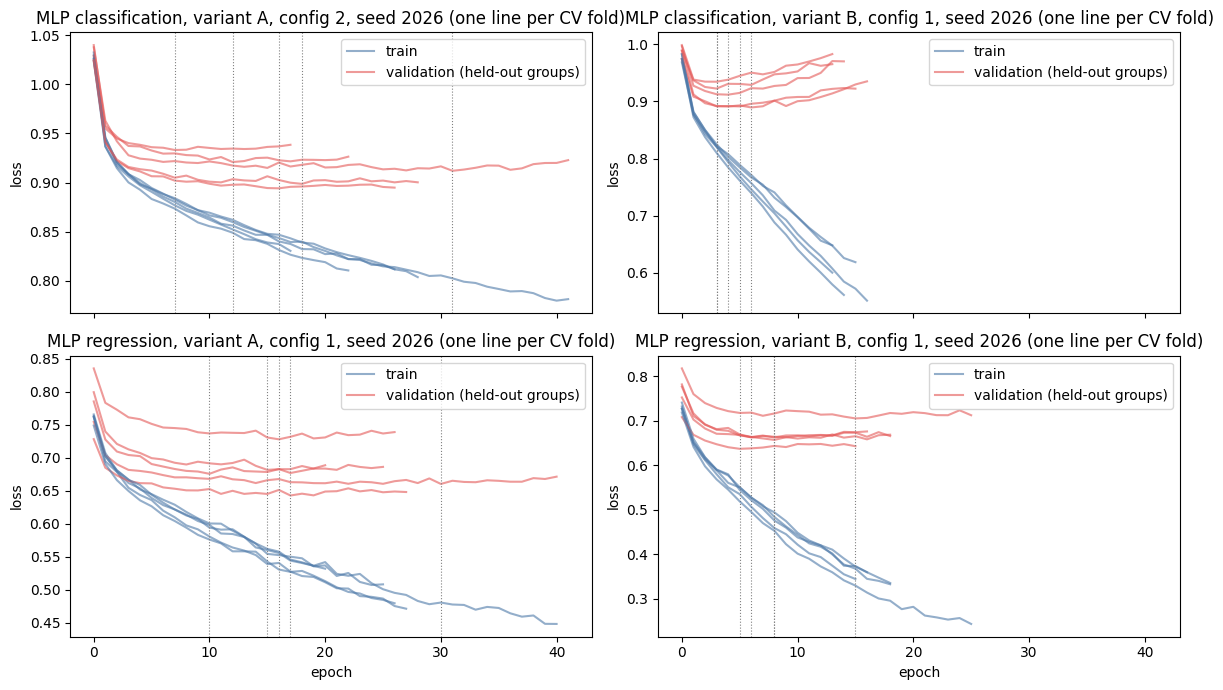

epochs used by the early stopping (all CV MLP fits):


count  mean   std  min   25%   50%   75%   max
task           variant                                                
classification A         45.0  13.4   8.3  4.0   7.0  11.0  16.0  39.0
               B         45.0   6.3   3.0  2.0   4.0   5.0   8.0  14.0
regression     A         45.0  20.0  10.4  7.0  11.0  17.0  28.0  47.0
               B         45.0  12.9   9.6  4.0   6.0   9.0  17.0  41.0

In [9]:
hist = cv["hist"]
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for (task, v), a in zip([(t, v) for t in ("classification", "regression") for v in ("A", "B")], ax.ravel()):
    cid = int(selection[(selection.variant == v) & (selection.task == task) & (selection.algo == "mlp")].cfg_id.iloc[0])
    for k in range(pe.N_FOLDS):
        h = hist[(v, task, "mlp", cid, "2026", k)]
        a.plot(h["train_loss"], color="#4c78a8", alpha=.6, label="train" if k == 0 else None); a.plot(h["val_loss"], color="#e45756", alpha=.6, label="validation (held-out groups)" if k == 0 else None)
        a.axvline(h["best_epoch"] - 1, color="grey", ls=":", lw=.8)
    a.set(title=f"MLP {task}, variant {v}, config {cid}, seed 2026 (one line per CV fold)", ylabel="loss"); a.legend()
for a in ax[1]: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(FIG / "mlp_loss_curves.png", dpi=130); plt.show()
H = pd.DataFrame([{"variant": k[0], "task": k[1], "config": k[3], "seed": k[4], "fold": k[5], "best_epoch": v["best_epoch"], "epochs_run": v["epochs_run"],
                   "final_train_loss": v["train_loss"][-1], "best_val_loss": min(v["val_loss"])} for k, v in hist.items()])
H.round(4).to_csv(pe.OUT / "mlp_cv_training_summary.csv", index=False)
print("epochs used by the early stopping (all CV MLP fits):"); display(H.groupby(["task", "variant"]).best_epoch.describe().round(1))

## 4. Fresh holdout (all models refit on the whole training pool with their CV-selected settings)

In [10]:
t0 = time.time()
hold_res = pe.run_holdout(df, manifest, selection, force=True)
print("holdout fits finished in %.0f s; training pool %d rows, holdout %d rows; tercile cut-offs from the pool: %s views" % (time.time() - t0, hold_res["pool_rows"], hold_res["holdout_rows"], np.round(hold_res["cuts"], 1)))
H = pe.holdout_tables(hold_res, df, selection)
for k in ("table", "seed_variability", "confusion", "by_genre", "bootstrap", "predictions"):
    H[k].round(5).to_csv(pe.OUT / {"table": "holdout_results.csv", "seed_variability": "holdout_mlp_seed_variability.csv", "confusion": "holdout_confusion_matrices.csv",
                                    "by_genre": "holdout_by_genre.csv", "bootstrap": "holdout_bootstrap_comparisons.csv", "predictions": "holdout_predictions.csv"}[k], index=False)
print("holdout class counts (low, medium, high):", H["holdout_class_counts"], "| pool class counts:", np.bincount(pe.to_class(df.set_index('identifier').loc[manifest[manifest.split=='pool'].identifier].views.values, np.array(hold_res['cuts'])), minlength=3).tolist())

  File "C:\Users\mhmd2\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1038, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1550, i

holdout fits finished in 82 s; training pool 14721 rows, holdout 3006 rows; tercile cut-offs from the pool: [ 70. 205.] views


holdout class counts (low, medium, high): [1058, 1017, 931] | pool class counts: [4922, 4906, 4893]


In [11]:
t = H["table"]
cl = t[t.task == "classification"].pivot(index="algo", columns="variant", values=["accuracy", "macro_f1"]).round(4)
cl["B-A accuracy"] = (cl[("accuracy","B")] - cl[("accuracy","A")]).round(4); cl["B-A macro_f1"] = (cl[("macro_f1","B")] - cl[("macro_f1","A")]).round(4)
print("HOLDOUT classification (low / medium / high); dummy = train-fitted baseline that always predicts the most common training class"); display(cl)
print("CV-selected classification winners:"); display(selection[(selection.task=="classification") & selection.is_variant_winner][["variant","algo","cfg","cv_value"]])

HOLDOUT classification (low / medium / high); dummy = train-fitted baseline that always predicts the most common training class


accuracy         macro_f1         B-A accuracy B-A macro_f1
variant        A       B        A       B                          
algo                                                               
dummy     0.3520  0.3520   0.1736  0.1736       0.0000       0.0000
hgb       0.5595  0.5689   0.5511  0.5607       0.0094       0.0096
logreg    0.5735  0.5935   0.5653  0.5852       0.0200       0.0199
mlp       0.5639  0.5645   0.5540  0.5488       0.0006      -0.0052

CV-selected classification winners:


,variant,algo,cfg,cv_value
2,A,logreg,"{""C"": 1.0}",0.563755
11,B,logreg,"{""C"": 1.0}",0.573151


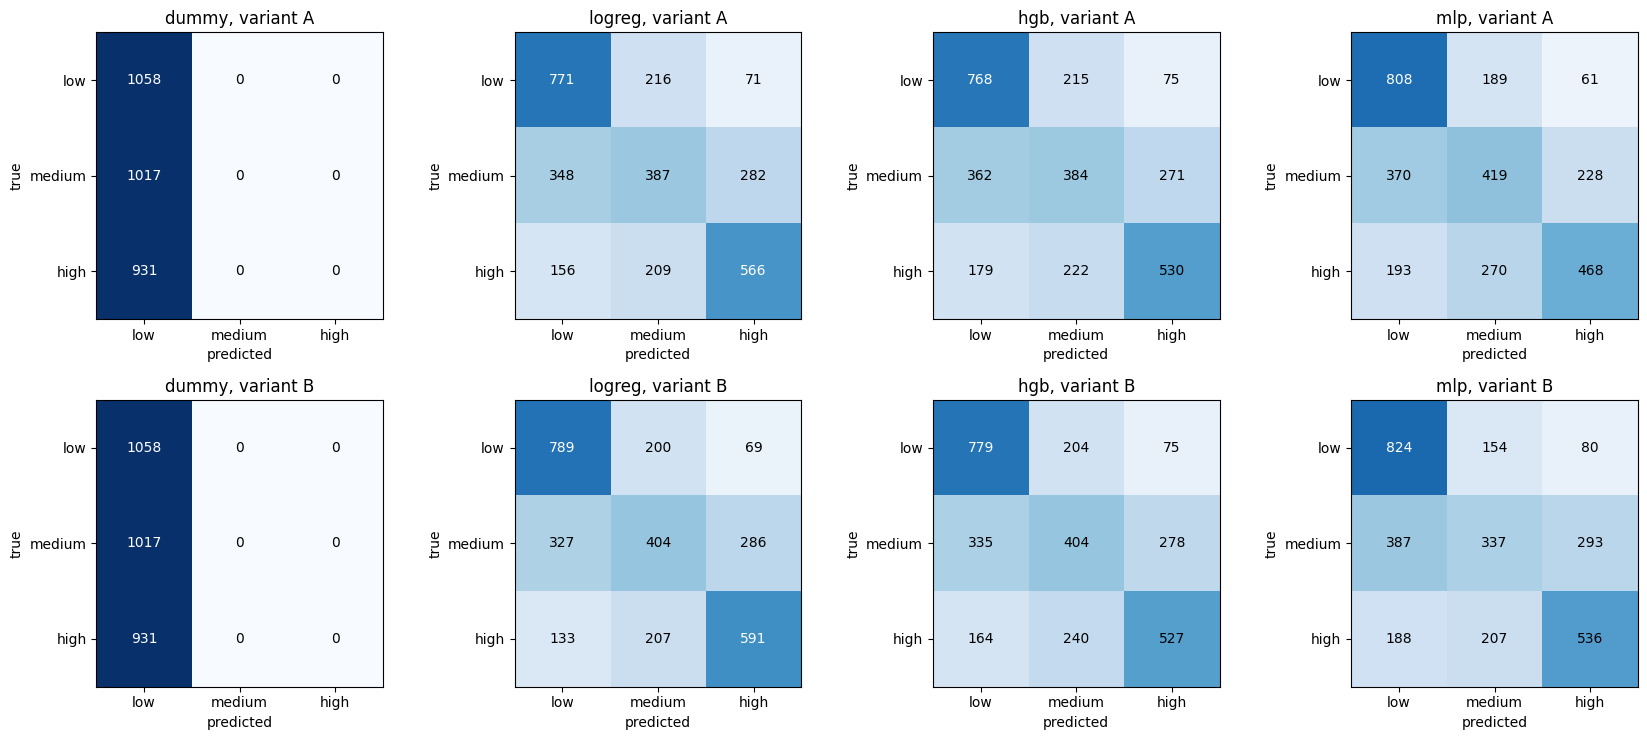

In [12]:
cm = H["confusion"]
fig, ax = plt.subplots(2, 4, figsize=(17, 7.5))
for i, v in enumerate(pe.VARIANTS):
    for j, a in enumerate(["dummy", "logreg", "hgb", "mlp"]):
        x = cm[(cm.variant == v) & (cm.algo == a)].set_index("true_class").loc[pe.CLASSES][[f"pred_{c}" for c in pe.CLASSES]].to_numpy()
        ax[i, j].imshow(x / x.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for p in range(3):
            for q in range(3): ax[i, j].text(q, p, str(x[p, q]), ha="center", va="center", color="black" if x[p, q] / x[p].sum() < .6 else "white")
        ax[i, j].set(xticks=range(3), yticks=range(3), xticklabels=pe.CLASSES, yticklabels=pe.CLASSES, title=f"{a}, variant {v}", xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.savefig(FIG / "holdout_confusion_matrices.png", dpi=130); plt.show()

In [13]:
g = H["by_genre"]; gc = g[g.task == "classification"].pivot_table(index=["algo", "genre"], columns="variant", values=["accuracy", "macro_f1"]).round(4)
print("Holdout classification by genre"); display(gc)

Holdout classification by genre


accuracy         macro_f1        
variant                        A       B        A       B
algo   genre                                             
dummy  fantasy            0.3356  0.3356   0.1675  0.1675
       mystery_thriller   0.4374  0.4374   0.2029  0.2029
       science_fiction    0.2827  0.2827   0.1469  0.1469
hgb    fantasy            0.5568  0.5597   0.5469  0.5515
       mystery_thriller   0.5696  0.5736   0.5353  0.5358
       science_fiction    0.5523  0.5734   0.5515  0.5727
logreg fantasy            0.5617  0.5824   0.5495  0.5698
       mystery_thriller   0.5956  0.6186   0.5688  0.5942
       science_fiction    0.5634  0.5795   0.5622  0.5786
mlp    fantasy            0.5577  0.5380   0.5491  0.5106
       mystery_thriller   0.5876  0.5846   0.5488  0.5433
       science_fiction    0.5463  0.5714   0.5490  0.5689

In [14]:
rg = t[t.task == "regression"].pivot(index="algo", columns="variant", values=["r2_log", "mae_views", "median_ae_views", "within_2x"]).round(4)
print("HOLDOUT regression: R2 on log1p(views); MAE / median absolute error in original views; within_2x = share of books with (estimate+1)/(views+1) between 0.5 and 2")
print("dummy_mean / dummy_median = train-fitted mean / median of log views"); display(rg)
print("CV-selected regression winners:"); display(selection[(selection.task=="regression") & selection.is_variant_winner][["variant","algo","cfg","cv_value"]])
gr = g[g.task == "regression"].pivot_table(index=["algo", "genre"], columns="variant", values=["r2_log", "median_ae_views"]).round(4)
print("Holdout regression by genre"); display(gr.loc[["ridge", "hgb", "mlp"]])

HOLDOUT regression: R2 on log1p(views); MAE / median absolute error in original views; within_2x = share of books with (estimate+1)/(views+1) between 0.5 and 2
dummy_mean / dummy_median = train-fitted mean / median of log views


r2_log         mae_views           median_ae_views          within_2x        
variant            A       B         A         B               A        B         A       B
algo                                                                                       
dummy_mean   -0.0054 -0.0054  296.8779  296.8779         91.0020  91.0020    0.4145  0.4145
dummy_median -0.0129 -0.0129  293.2595  293.2595         72.0000  72.0000    0.4568  0.4568
hgb           0.3225  0.3468  265.3841  264.6634         61.7226  61.4676    0.5765  0.5818
mlp           0.3048  0.3322  267.5656  267.1091         61.6794  59.2726    0.5695  0.5885
ridge         0.3997  0.4186  257.3961  255.3663         58.5070  59.2932    0.6075  0.6158

CV-selected regression winners:


,variant,algo,cfg,cv_value
8,A,ridge,"{""alpha"": 3.0}",0.400648
17,B,ridge,"{""alpha"": 3.0}",0.418684


Holdout regression by genre


median_ae_views           r2_log        
variant                              A        B       A       B
algo  genre                                                    
ridge fantasy                  65.2158  67.9190  0.3872  0.4155
      mystery_thriller         43.5972  43.3204  0.3569  0.3636
      science_fiction          69.6413  70.1979  0.4035  0.4219
hgb   fantasy                  72.4609  69.8241  0.3108  0.3360
      mystery_thriller         46.4168  46.7600  0.3001  0.3203
      science_fiction          76.5950  73.8433  0.3024  0.3309
mlp   fantasy                  72.3136  65.7435  0.2813  0.3130
      mystery_thriller         45.0032  45.1295  0.3074  0.3236
      science_fiction          75.1708  71.8542  0.2776  0.3108

### Is a difference reliable? Group-level bootstrap on the holdout (1,000 resamples of work groups; the same books for A and B)
Intervals that include 0 mean the difference is not distinguishable from noise on this holdout.

In [15]:
b = H["bootstrap"]
cols_c = ["accuracy_mean", "accuracy_lo95", "accuracy_hi95", "macro_f1_mean", "macro_f1_lo95", "macro_f1_hi95"]
cols_r = ["r2_log_mean", "r2_log_lo95", "r2_log_hi95", "median_ae_views_mean", "median_ae_views_lo95", "median_ae_views_hi95", "within_2x_mean", "within_2x_lo95", "within_2x_hi95"]
pd.set_option("display.max_rows", 100)
print("CLASSIFICATION differences (second minus first)"); display(b[b.task == "classification"][["comparison", "detail"] + cols_c].round(4))
print("REGRESSION differences (second minus first)"); display(b[b.task == "regression"][["comparison", "detail"] + cols_r].round(4))

CLASSIFICATION differences (second minus first)


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95
0,"description effect (B - A), same algorithm",dummy,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,"description effect (B - A), same algorithm",logreg,0.0202,0.0069,0.0339,0.0202,0.0064,0.0344
2,"description effect (B - A), same algorithm",hgb,0.0091,-0.0057,0.0237,0.0094,-0.0068,0.0245
3,"description effect (B - A), same algorithm",mlp,0.0009,-0.0130,0.0156,-0.0050,-0.0189,0.0105
4,CV-selected winners (B winner - A winner),logreg (B) vs logreg (A),0.0202,0.0069,0.0339,0.0202,0.0064,0.0344
5,"neural network minus best non-neural model by CV, variant A",mlp - logreg,-0.0100,-0.0273,0.0066,-0.0117,-0.0288,0.0056
6,"model minus train-fitted baseline (dummy), variant A",logreg,0.2220,0.1988,0.2436,0.3919,0.3733,0.4092
7,"model minus train-fitted baseline (dummy), variant A",hgb,0.2080,0.1858,0.2290,0.3776,0.3602,0.3954
8,"model minus train-fitted baseline (dummy), variant A",mlp,0.2120,0.1909,0.2333,0.3802,0.3617,0.3984
9,"neural network minus best non-neural model by CV, variant B",mlp - logreg,-0.0293,-0.0463,-0.0120,-0.0369,-0.0552,-0.0183


REGRESSION differences (second minus first)


,comparison,detail,r2_log_mean,r2_log_lo95,r2_log_hi95,median_ae_views_mean,median_ae_views_lo95,median_ae_views_hi95,within_2x_mean,within_2x_lo95,within_2x_hi95
13,"description effect (B - A), same algorithm",dummy_mean,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
14,"description effect (B - A), same algorithm",dummy_median,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
15,"description effect (B - A), same algorithm",ridge,0.0191,0.0075,0.0317,0.8180,-1.8635,3.5118,0.0083,-0.0053,0.0211
16,"description effect (B - A), same algorithm",hgb,0.0247,0.0104,0.0388,-0.3253,-2.6610,2.0748,0.0052,-0.0076,0.0181
17,"description effect (B - A), same algorithm",mlp,0.0274,0.0091,0.0449,-2.7600,-5.3271,-0.2239,0.0192,0.0063,0.0337
18,CV-selected winners (B winner - A winner),ridge (B) vs ridge (A),0.0191,0.0075,0.0317,0.8180,-1.8635,3.5118,0.0083,-0.0053,0.0211
19,"neural network minus best non-neural model by CV, variant A",mlp - ridge,-0.0948,-0.1187,-0.0710,3.3388,0.1024,6.3363,-0.0380,-0.0551,-0.0227
20,"model minus train-fitted baseline (dummy_mean), variant A",ridge,0.4053,0.3710,0.4358,-32.9152,-36.5523,-29.0109,0.1926,0.1722,0.2129
21,"model minus train-fitted baseline (dummy_mean), variant A",hgb,0.3281,0.2935,0.3603,-29.6707,-33.1595,-26.0626,0.1618,0.1422,0.1815
22,"model minus train-fitted baseline (dummy_mean), variant A",mlp,0.3105,0.2774,0.3424,-29.5765,-32.7535,-26.2923,0.1546,0.1346,0.1733


In [16]:
sv = H["seed_variability"]
print("MLP on the holdout, one row per predeclared seed (the reported MLP result is the average of the three seeds, not the best seed)")
display(sv.groupby(["task", "variant"]).agg(**{k: (k, f) for k in ["accuracy", "macro_f1", "r2_log", "median_ae_views"] if k in sv.columns for f in ["mean"]}).round(4))
display(sv.groupby(["task", "variant"])[[c for c in ["accuracy", "macro_f1", "r2_log"] if c in sv.columns]].agg(["min", "max"]).round(4))

MLP on the holdout, one row per predeclared seed (the reported MLP result is the average of the three seeds, not the best seed)


accuracy  macro_f1  r2_log  median_ae_views
task           variant                                             
classification A          0.5551    0.5456     NaN              NaN
               B          0.5607    0.5454     NaN              NaN
regression     A             NaN       NaN  0.2912          62.2498
               B             NaN       NaN  0.3159          60.5848

accuracy         macro_f1          r2_log        
                            min     max      min     max     min     max
task           variant                                                  
classification A         0.5529  0.5572   0.5392  0.5501     NaN     NaN
               B         0.5579  0.5652   0.5360  0.5567     NaN     NaN
regression     A            NaN     NaN      NaN     NaN  0.2845  0.2951
               B            NaN     NaN      NaN     NaN  0.3109  0.3213

## 5. Grouped learning curves (training pool only; the holdout is not used)

learning curves finished in 271 s


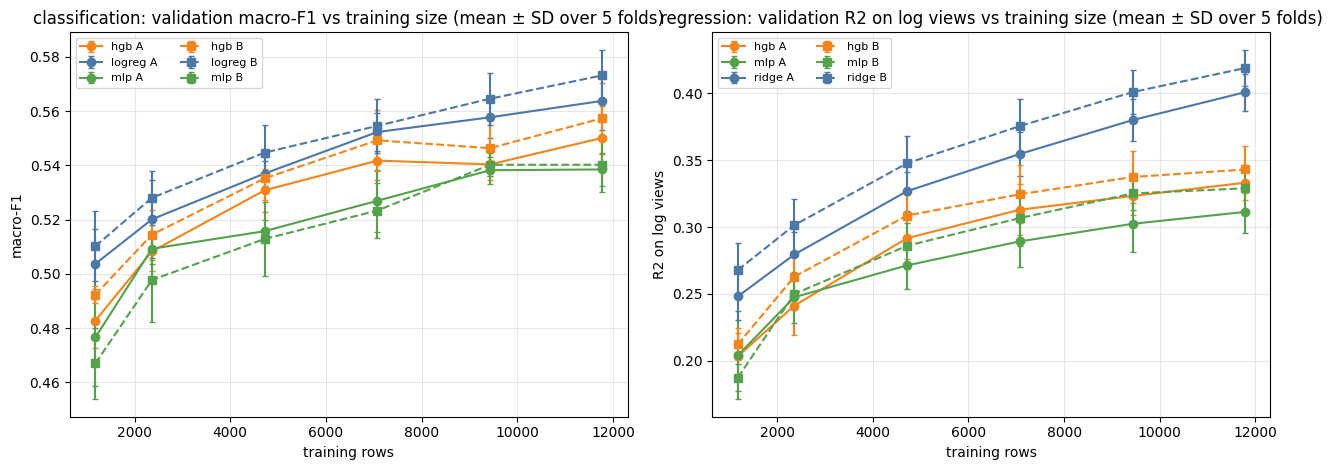

rows  macro_f1  r2_log
task           variant algo   fraction                           
classification A       hgb    0.4        4715.2    0.5308     NaN
                              1.0       11776.8    0.5501     NaN
                       logreg 0.4        4715.2    0.5370     NaN
                              1.0       11776.8    0.5638     NaN
                       mlp    0.4        4715.2    0.5157     NaN
                              1.0       11776.8    0.5385     NaN
               B       hgb    0.4        4715.2    0.5352     NaN
                              1.0       11776.8    0.5574     NaN
                       logreg 0.4        4715.2    0.5447     NaN
                              1.0       11776.8    0.5732     NaN
                       mlp    0.4        4715.2    0.5128     NaN
                              1.0       11776.8    0.5402     NaN
regression     A       hgb    0.4        4715.2       NaN  0.2916
                              1.0       11776.8       NaN  0.3331
                       mlp    0.4        4715.2       NaN  0.2713
                              1.0       11776.8       NaN  0.3113
                       ridge  0.4        4715.2       NaN  0.3267
                              1.0       11776.8       NaN  0.4006
               B       hgb    0.4        4715.2       NaN  0.3086
                              1.0       11776.8       NaN  0.3430
                       mlp    0.4        4715.2       NaN  0.2860
                              1.0       11776.8       NaN  0.3289
                       ridge  0.4        4715.2       NaN  0.3476
                              1.0       11776.8       NaN  0.4187

In [17]:
t0 = time.time()
lc = pe.run_learning_curves(df, manifest, selection, n_jobs=5, force=True); lc.round(5).to_csv(pe.OUT / "learning_curves.csv", index=False)
print("learning curves finished in %.0f s" % (time.time() - t0))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
col = {"logreg": "#4c78a8", "ridge": "#4c78a8", "hgb": "#f58518", "mlp": "#54a24b"}
for a, (task, metric, lab) in zip(ax, [("classification", "macro_f1", "macro-F1"), ("regression", "r2_log", "R2 on log views")]):
    for (v, algo), g in lc[lc.task == task].groupby(["variant", "algo"]):
        s = g.groupby("fraction").agg(rows=("train_rows", "mean"), m=(metric, "mean"), sd=(metric, "std"))
        a.errorbar(s.rows, s.m, yerr=s.sd, color=col[algo], ls="-" if v == "A" else "--", marker="o" if v == "A" else "s", capsize=2, label=f"{algo} {v}")
    a.set(title=f"{task}: validation {lab} vs training size (mean ± SD over 5 folds)", xlabel="training rows", ylabel=lab); a.legend(ncol=2, fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "learning_curves.png", dpi=130); plt.show()
last = lc[lc.fraction.isin([0.4, 1.0])].groupby(["task", "variant", "algo", "fraction"]).agg(rows=("train_rows", "mean"), macro_f1=("macro_f1", "mean"), r2_log=("r2_log", "mean")).round(4); display(last)

## 6. Training times

In [18]:
r1 = res[res.seed.astype(str).isin(["single", "avg"])].merge(selection[["variant", "task", "algo", "cfg_id"]], on=["variant", "task", "algo", "cfg_id"])
r1 = r1.assign(per_seed=np.where(r1.algo == "mlp", r1.fit_seconds / len(pe.MLP_SEEDS), r1.fit_seconds))
tm = r1.groupby(["task", "algo", "variant"]).agg(cv_model_fit_s_per_fold=("fit_seconds", "mean"), cv_fit_s_per_seed_or_model=("per_seed", "mean")).round(2)
fin = pd.DataFrame(hold_res["records"]); fin = fin[fin.seed.astype(str).isin(["single", "avg"])].set_index(["task", "algo", "variant"]).fit_seconds.round(2).rename("final_fit_s_on_pool")
tm = tm.join(fin); tm.to_csv(pe.OUT / "training_times.csv"); display(tm)
print("Feature construction (TF-IDF, SVD, scaling) for A and B together, seconds per CV fold:", fi.set_index("fold").index.size, "folds; mean %.1f s" % res.groupby("fold").feature_seconds.first().mean(), "| final pool: %.1f s" % hold_res["feature_seconds"])
print("MLP fit time is the sum over the three seeds in 'cv_model_fit_s_per_fold'; CPU only.")

cv_model_fit_s_per_fold  cv_fit_s_per_seed_or_model  final_fit_s_on_pool
task           algo         variant                                                                          
classification dummy        A                           0.00                        0.00                 0.00
                            B                           0.00                        0.00                 0.00
               hgb          A                           7.77                        7.77                 3.76
                            B                          16.18                       16.18                 9.46
               logreg       A                           1.33                        1.33                 1.61
                            B                           3.48                        3.48                 3.37
               mlp          A                          15.89                        5.30                17.21
                            B                           8.81                        2.94                 8.18
regression     dummy_mean   A                           0.00                        0.00                 0.00
                            B                           0.00                        0.00                 0.00
               dummy_median A                           0.00                        0.00                 0.00
                            B                           0.00                        0.00                 0.00
               hgb          A                           2.24                        2.24                 1.26
                            B                           5.03                        5.03                 3.20
               mlp          A                          14.25                        4.75                17.36
                            B                          10.92                        3.64                10.19
               ridge        A                           0.06                        0.06                 0.07
                            B                           0.25                        0.25                 0.29

Feature construction (TF-IDF, SVD, scaling) for A and B together, seconds per CV fold: 5 folds; mean 7.5 s | final pool: 5.9 s
MLP fit time is the sum over the three seeds in 'cv_model_fit_s_per_fold'; CPU only.


## 7. Findings

All numbers below are from this executed notebook (fresh holdout: 3,006 items / 2,886 works that are not in the earlier 5,600-book dataset; training pool 14,721 items). Tercile cut-offs fitted on the pool: low ≤ 70 views, high > 205 views. Holdout classes: 1,058 low / 1,017 medium / 931 high.

**Models chosen by cross-validation only (before the holdout was scored; `cv_selection_written_utc.txt` is earlier than the holdout files).** Classification: LogisticRegression (C = 1) in both variants. Regression: Ridge (alpha = 3) in both variants. HistGradientBoosting and the MLP came second and third in CV.

| Holdout | Dummy baseline | A: metadata | B: metadata + description |
|---|---|---|---|
| Classification accuracy, CV-selected LogReg | 35.2 % (always "low") | 57.4 % | **59.4 %** |
| Classification macro-F1, LogReg | 0.174 | 0.565 | **0.585** |
| Regression R² on log views, CV-selected Ridge | −0.005 (mean) | 0.400 | **0.419** |
| Median absolute error, views (Ridge) | 91 (mean) / 72 (median) | 58.5 | 59.3 |
| Within a factor of 2 (Ridge) | 41 % / 46 % | 60.7 % | 61.6 % |

**Do descriptions help?** A little, and not for every model or metric.
* Classification: +2.0 accuracy points for LogReg (group-bootstrap 95 % interval +0.7 to +3.4; B beat A in 5 of 5 CV folds, +0.9 points on average in CV). For HistGradientBoosting the holdout gain is +0.9 points (interval −0.6 to +2.4) and for the MLP +0.1 points (−1.3 to +1.6): not distinguishable from zero.
* Regression: R² on log views improves by about 0.02–0.03 for Ridge, HGB and MLP (all intervals exclude 0; B better in 5 of 5 folds for all three). The typical error in views does not improve reliably (median absolute error intervals include 0, except the MLP, −2.8 views), and the within-2x rate gains only about one percentage point. So descriptions help rank books slightly better on the log scale; they do not make view counts much more precise.
* The description effect is small compared with the effect of the metadata itself: both variants are about 22 points of accuracy above the baseline (A: +22.2, B: +24.2). The collected metadata (years on the archive, scan size, subjects, authors) carries most of the signal.

**Does the neural network beat the other models? No.** Under CV the MLP ranked third for classification in both variants and for regression in A, and second (just ahead of HGB, 0.345 vs 0.343) for regression in B; Ridge/LogReg ranked first every time. On the holdout the CV-selected non-neural model is better or equal: classification, MLP minus LogReg −1.0 points in A (interval −2.7 to +0.7) and −2.9 points in B (−4.6 to −1.2); regression, MLP minus Ridge R² −0.095 in A and −0.087 in B (both intervals exclude 0). The three MLP seeds agree closely (holdout accuracy 55.3–56.5 %, R² 0.285–0.321), so this is not a bad-seed effect. The MLP is also slower than LogReg/Ridge to train (about 3–5 s per seed, versus 1–3.5 s for LogReg and under 0.3 s for Ridge) and gains nothing from descriptions in classification. The result applies to this small architecture, this input representation (TF-IDF compressed to 100 SVD components) and this bounded search; it does not show that no neural network could do better.

**How good is it?** Roughly 59 % for three-class accuracy, against a 35 % baseline, and R² 0.42 on log views. This is far from the 85 % once hoped for. Most mistakes are to the neighbouring class (for example LogReg B recognises 40 % of the true "medium" books but 63 % of "high" and 75 % of "low" books). Genre accuracy from earlier experiments is not popularity accuracy.

**Learning curves (training pool, grouped folds).** Macro-F1 rises quickly up to about 40 % of the data and then slowly (LogReg A 0.537 at 40 % to 0.564 at 100 %; B 0.545 to 0.573). Ridge R² was still rising between 80 % and 100 % (A 0.380 to 0.401). The curves show that more data may give small further gains for the linear models but do not guarantee them, and the gap between A and B stays about the same size at every training size.

**Limitations.**
* The target is all-time views of an archived copy, which reflects archive age, scan type and what the site shows, not sales, readership or the future success of a book. Archive age is an input, so this is not a prediction for new publications.
* The holdout comes only from newly collected works, which have lower views than the older part of the pool (so the baseline is 35 %, not 33 %). CV scores (LogReg B 57.3 % macro-F1 in CV) and holdout scores are therefore not the same quantity; differences between them should not be over-read.
* Author overlap between works is allowed (as in a real catalogue), so author inputs carry some "known author" signal. Genre flags and the juvenile marker are rule-based from subject tags; the description-ready filter is automated, and some descriptions are contents lists rather than blurbs.
* The search was deliberately small and identical for A and B (4 Logistic/Ridge settings, 3 settings each for HGB and MLP, 3 MLP seeds). The best HGB setting was the deepest one tried, so a larger search might improve the trees; no tuning used the holdout.
* One fixed holdout with bootstrap intervals over works, not repeated sampling; intervals do not include uncertainty from the choice of holdout.
* Differences of one or two points are small relative to this uncertainty; treat them as suggestive evidence, not proof.

## 8. Reproduce
```bash
pip install -r requirements-analysis.txt            # pandas, scikit-learn, torch (CPU), jupyter ...
python scrapers/prepare_popularity_dataset.py        # optional: rebuilds data/popularity_training_clean.csv offline
cd notebooks && jupyter nbconvert --to notebook --execute --inplace 05_popularity_description_comparison.ipynb   # about 15-25 minutes on 16 CPU threads
```
Seeds: split/CV seed 2026; MLP seeds 2026, 2027, 2028 (predeclared). Package versions: `report/ml/environment.json`. Result tables and figures: `report/ml/` (`split_manifest.csv`, `cv_*.csv`, `holdout_*.csv`, `learning_curves.csv`, `training_times.csv`, `figures/`).
Delete `report/ml/cache/` before re-running to force every stage to recompute (the notebook already forces recomputation).

## 9. Try a book yourself — type the details by hand

**Run only the three cells below. You do not need to rerun the earlier training experiment.**

1. Run **Setup** once per notebook session. It prepares the recorded CV-selected LogisticRegression and Ridge models on the saved 14,721-item training pool (no scraping, CV search or holdout fitting).
2. Edit **BOOK**: the preset is a real training item, Fahrenheit 451; replace its title and description to enter your own book. Author, year, pages, genre, subjects and years on the archive are optional.
3. Run **Predict** to compare **without description** and **with description**. Change BOOK and rerun the last two cells for another book.

You can enter only `title` and `description`. Missing numeric metadata uses training-pool medians, shown in an assumptions table; entering the real values makes the estimate more specific. A blank description produces only the metadata-model prediction. `archive_years` means time available on Internet Archive, not the book's publication age.

The output estimates **existing archived-item engagement at the entered/assumed archive age**, not future sales. The popularity class and approximate view count come from separate models. Percentages are model probabilities, not guarantees. These demo predictions do not add rows to the dataset or change any reported result.

### Setup — run once

**Two verified real examples are below in section 10:** a training item and an unseen held-out work, with observed views shown separately after prediction.


In [ ]:
from pathlib import Path
import sys
from IPython.display import display

notebook_dir = Path.cwd() if (Path.cwd() / "manual_book_prediction.py").exists() else Path.cwd() / "notebooks"
if not (notebook_dir / "manual_book_prediction.py").exists():
    raise FileNotFoundError("Open this notebook inside the project repository (root or notebooks/).")
sys.path.insert(0, str(notebook_dir))
import importlib
import manual_book_prediction
importlib.reload(manual_book_prediction)
from manual_book_prediction import ManualBookPredictor

book_predictor = ManualBookPredictor.from_project()


### BOOK — edit your details here


In [5]:
# Real Internet Archive training example. Edit these fields to try your own book.
# Source: https://archive.org/details/fahrenheit4510000brad
# Saved observed views: 19245 (kept out of model inputs).
# Use description="" to try this book without a description.
BOOK = {
    'title': 'Fahrenheit 451',
    'description': 'Fireman Guy Montag is a fireman whose job it is to start fires. And he loves to rush to a fire and watch books burn, along with the houses in which they were hidden. Then he meets a seventeen-year old girl who tells him of a past when people were not afraid, and a professor who tells him of a future where people can think. And Guy Montag knows what he has to do .. "Fahrenheit 451-- the temperature at which book paper catches fire, and burns--" "A Del Rey book." Includes an afterword, coda, and interview with Ray Bradbury by Linda Del Rey Edition statement from cover',
    'author': 'Bradbury, Ray, 1920-2012',
    'publication_year': 2003,
    'pages': 214,
    'genre': None,
    'subjects': 'State-sponsored terrorism -- Fiction | Totalitarianism -- Fiction | Book burning -- Fiction | Censorship -- Fiction | Book burning | Censorship | State-sponsored terrorism | Totalitarianism | Science Fiction -- Fiction',
    'archive_years': 6.2121834360027375,
    'juvenile': False,
}


### Predict — rerun after editing BOOK


In [6]:
if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell above once, then edit BOOK and run this cell.")

answer = book_predictor.predict_book(**BOOK)
print("Book:", BOOK["title"])
display(answer["predictions"])
cuts = answer["class_cutoffs"]
print(f"Class definitions from the training pool: low <= {cuts['low_max']:g} views; "
      f"medium > {cuts['low_max']:g} and <= {cuts['medium_max']:g}; high > {cuts['medium_max']:g}.")
if not answer["assumptions"].empty:
    print("Missing details / assumptions used:")
    display(answer["assumptions"])


Book: Fahrenheit 451


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%)
0,Without description,high,712,22.9,32.0,45.1
1,With description,high,1086,17.8,24.7,57.4


Class definitions from the training pool: low <= 70 views; medium > 70 and <= 205; high > 205.


## 10. Two real Internet Archive examples

Run the updated **Setup** cell in section 9 once, then run either example below. Each cell loads the exact saved metadata, including description, author, year, page count, subject tags and archive age. No website request is made and there are no guessed median values.

The first book was used for fitting the model. It is a familiar-example check, **not** evidence of generalisation. The second was excluded from fitting, including all items with its Open Library work ID; it was used only for the held-out evaluation. It is a genuine unseen-work test, not a newly scraped item outside the whole dataset.

Observed views are taken from the saved API snapshot and attached **after** prediction, never passed as an input. Current website counters may differ. A pair of examples illustrates behaviour; the full held-out metrics remain the accuracy measurement.


### 10.1 Training example — Fahrenheit 451

[Open this archived item](https://archive.org/details/fahrenheit4510000brad). Saved observed views: **19,245**, class **high**.


In [2]:
if "book_predictor" not in globals() or not hasattr(book_predictor, "predict_archive_example"):
    raise RuntimeError("Run the updated Setup cell in section 9 first.")

training_demo = book_predictor.predict_archive_example("training")
BOOK = training_demo["book"].copy()   # Exact inputs; you can edit this BOOK and use the manual Predict cell.
ref = training_demo["reference"]
print("Book:", ref["title"])
print("Source:", ref["item_url"])
print("Data role:", ref["split"])
print("Observed views:", ref["observed_archive_views"], "| observed class:", ref["observed_popularity"])
print("Observed at (UTC):", ref["observed_at_utc"])
display(training_demo["predictions"])


Book: Fahrenheit 451
Source: https://archive.org/details/fahrenheit4510000brad
Data role: training pool
Observed views: 19245 | observed class: high
Observed at (UTC): 2026-11-22T15:57:56Z


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,high,712,22.9,32.0,45.1,19245,high,True,18533
1,With description,high,1086,17.8,24.7,57.4,19245,high,True,18159


### 10.2 Unseen held-out example — The Time Machine and the Invisible Man

[Open this archived item](https://archive.org/details/timemachineinvis0000well_p4k8). Saved observed views: **87**, class **medium**.


In [3]:
if "book_predictor" not in globals() or not hasattr(book_predictor, "predict_archive_example"):
    raise RuntimeError("Run the updated Setup cell in section 9 first.")

holdout_demo = book_predictor.predict_archive_example("holdout")
BOOK = holdout_demo["book"].copy()   # Exact inputs; you can edit this BOOK and use the manual Predict cell.
ref = holdout_demo["reference"]
print("Book:", ref["title"])
print("Source:", ref["item_url"])
print("Data role:", ref["split"])
print("Observed views:", ref["observed_archive_views"], "| observed class:", ref["observed_popularity"])
print("Observed at (UTC):", ref["observed_at_utc"])
display(holdout_demo["predictions"])


Book: The time machine and the invisible man
Source: https://archive.org/details/timemachineinvis0000well_p4k8
Data role: held-out test set (work not trained on)
Observed views: 87 | observed class: medium
Observed at (UTC): 2026-11-22T16:01:23Z


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,medium,110,22.1,54.7,23.2,87,medium,True,23
1,With description,medium,131,18.0,52.5,29.5,87,medium,True,44


### 10.3 (Claude) Training example without description — The Hobbit

[Open this archived item](https://archive.org/details/hobbitortherebac0000tolk_b9p5). Observed all-time views: **2,496** (class **high**), shown only after the prediction.

This book **was in the training pool**, so the result is a familiar-example check, not evidence of generalisation. The cell passes `description=""`, so only the **without-description** model runs. The saved description has 33 words; paste it into BOOK to compare.

In [13]:
# Training example without description — The Hobbit
# Source: https://archive.org/details/hobbitortherebac0000tolk_b9p5
# Description left empty on purpose (33 saved words exist). Paste one into BOOK to compare.
BOOK = {'title': 'The hobbit : or there and back again',
 'description': '',
 'author': 'Tolkien, J. R. R. (John Ronald Reuel), 1892-1973',
 'publication_year': 2008,
 'pages': 430,
 'genre': None,
 'subjects': 'Baggins, Bilbo -- Fiction | Baggins, Bilbo | Hobbits (Fictitious characters) -- Fiction | Fantasy fiction | Hobbits '
             '(Fictitious characters)',
 'archive_years': 4.933607118412047,
 'juvenile': False}
OBSERVED_VIEWS = 2496   # observed on archive.org; used only for the comparison below, never as a model input

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell in section 9 first.")
answer = book_predictor.predict_book(**BOOK)
cuts = answer["class_cutoffs"]
observed_class = "low" if OBSERVED_VIEWS <= cuts["low_max"] else ("high" if OBSERVED_VIEWS > cuts["medium_max"] else "medium")
table = answer["predictions"].copy()
table["Observed archive views"] = OBSERVED_VIEWS
table["Observed popularity"] = observed_class
table["Class matches observed?"] = table["Predicted popularity"] == observed_class
table["Absolute view-count error"] = (table["Estimated archive views"] - OBSERVED_VIEWS).abs()
print("Book:", BOOK["title"])
display(table)
print(f"Classes: low <= {cuts['low_max']:g} views; medium > {cuts['low_max']:g} and <= {cuts['medium_max']:g}; high > {cuts['medium_max']:g}.")
if not answer["assumptions"].empty:
    print("Missing details / assumptions used:")
    display(answer["assumptions"])

Book: The hobbit : or there and back again


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,high,1165,3.6,6.6,89.7,2496,high,True,1331


Classes: low <= 70 views; medium > 70 and <= 205; high > 205.
Missing details / assumptions used:


,input,value_used,reason
0,description,not supplied,only the without-description model is shown


### 10.4 (Claude) Outside example without description — The Big Sleep

[Open this archived item](https://archive.org/details/bigsleep0000chan_m2k7). Observed all-time views: **4,127** (class **high**), shown only after the prediction.

This book is **outside everything we collected**: its identifier and its Open Library work are in none of our CSVs, the manifests, or the training/holdout split. Its details come from the 22 Nov 2026 archive.org catalogue snapshot (`data/manifest/ol_pool_snapshot_20261122.csv.gz`); the views were read from archive.org's views API on 22 Nov 2026 18:51 UTC. The cell passes `description=""`, so only the **without-description** model runs. The saved description has 28 words; paste it into BOOK to compare.

In [14]:
# Outside example without description — The Big Sleep
# Source: https://archive.org/details/bigsleep0000chan_m2k7
# Description left empty on purpose (28 saved words exist). Paste one into BOOK to compare.
BOOK = {'title': 'The big sleep',
 'description': '',
 'author': 'Chandler, Raymond, 1888-1959',
 'publication_year': 2004,
 'pages': 278,
 'genre': None,
 'subjects': 'Marlowe, Philip (Fictitious character) -- Fiction | Private investigators -- California -- Fiction | Detective and mystery '
             'stories, American | Détectives -- Californie -- Romans, nouvelles, etc | Private investigators | California',
 'archive_years': 4.167008898015058,
 'juvenile': False}
OBSERVED_VIEWS = 4127   # observed on archive.org; used only for the comparison below, never as a model input

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell in section 9 first.")
answer = book_predictor.predict_book(**BOOK)
cuts = answer["class_cutoffs"]
observed_class = "low" if OBSERVED_VIEWS <= cuts["low_max"] else ("high" if OBSERVED_VIEWS > cuts["medium_max"] else "medium")
table = answer["predictions"].copy()
table["Observed archive views"] = OBSERVED_VIEWS
table["Observed popularity"] = observed_class
table["Class matches observed?"] = table["Predicted popularity"] == observed_class
table["Absolute view-count error"] = (table["Estimated archive views"] - OBSERVED_VIEWS).abs()
print("Book:", BOOK["title"])
display(table)
print(f"Classes: low <= {cuts['low_max']:g} views; medium > {cuts['low_max']:g} and <= {cuts['medium_max']:g}; high > {cuts['medium_max']:g}.")
if not answer["assumptions"].empty:
    print("Missing details / assumptions used:")
    display(answer["assumptions"])

Book: The big sleep


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,low,131,40.7,25.5,33.8,4127,high,False,3996


Classes: low <= 70 views; medium > 70 and <= 205; high > 205.
Missing details / assumptions used:


,input,value_used,reason
0,description,not supplied,only the without-description model is shown


### 10.5 (Claude) Training example with description — Neuromancer

[Open this archived item](https://archive.org/details/neuromancer0000gibs_b5r9). Observed all-time views: **2,714** (class **high**), shown only after the prediction.

This book **was in the training pool**, so the result is a familiar-example check, not evidence of generalisation. The full description is in BOOK, so **both** models run: without description and with description.

In [15]:
# Training example with description — Neuromancer
# Source: https://archive.org/details/neuromancer0000gibs_b5r9
BOOK = {'title': 'Neuromancer',
 'description': 'Henry Dorsett Case was the sharpest data-thief in the Matrix, until an ex-employer crippled his nervous system. Now a new '
                'employer has recruited him for a last-chance run against an unthinkably powerful artificial intelligence. With a '
                "mirror-eyed girl street-samurai riding shotgun, he's ready for the silicon-quick, bleakly prophetic adventure that upped "
                'the ante on an entire genre of fiction Henry Dorsett Case was the sharpest data-thief in the Matrix, until an ex-employer '
                'crippled his nervous system. Recruited for a last-chance run against an unthinkably powerful artificial intelligence, '
                'Case needs to complete the mission to stay alive. Molly, with mirror-shade implants and razors in her fingertips, riding '
                'shotgun, is going to keep him alive... if she can. -- adapted from introduction Series introduction: What we talk about '
                'when we talk about science fiction / by Neil Gaiman -- Neuromancer. Chiba City blues ; The shopping expedition ; Midnight '
                'in the Rue James Verne ; The straylight run ; Coda: Departure and arrival',
 'author': 'Gibson, William, 1948- author',
 'publication_year': 2016,
 'pages': 314,
 'genre': None,
 'subjects': 'Nervous system -- Wounds and injuries -- Fiction | Information superhighway -- Fiction | Business intelligence -- Fiction | '
             'Conspiracies -- Fiction | Hackers -- Fiction | Système nerveux -- Lésions et blessures -- Romans, nouvelles, etc | '
             'Autoroutes électroniques -- Romans, nouvelles, etc | Conspiration -- Romans, nouvelles, etc | Pirates informatiques -- '
             'Romans, nouvelles, etc | Science fiction | Business intelligence | Conspiracies | Hackers | Information superhighway | '
             'Nervous system -- Wounds and injuries | Nervous system -- Fiction | Information networks -- Fiction | Political crimes and '
             'offenses -- Fiction | Japan -- Fiction | Japan',
 'archive_years': 4.566735112936345,
 'juvenile': False}
OBSERVED_VIEWS = 2714   # observed on archive.org; used only for the comparison below, never as a model input

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell in section 9 first.")
answer = book_predictor.predict_book(**BOOK)
cuts = answer["class_cutoffs"]
observed_class = "low" if OBSERVED_VIEWS <= cuts["low_max"] else ("high" if OBSERVED_VIEWS > cuts["medium_max"] else "medium")
table = answer["predictions"].copy()
table["Observed archive views"] = OBSERVED_VIEWS
table["Observed popularity"] = observed_class
table["Class matches observed?"] = table["Predicted popularity"] == observed_class
table["Absolute view-count error"] = (table["Estimated archive views"] - OBSERVED_VIEWS).abs()
print("Book:", BOOK["title"])
display(table)
print(f"Classes: low <= {cuts['low_max']:g} views; medium > {cuts['low_max']:g} and <= {cuts['medium_max']:g}; high > {cuts['medium_max']:g}.")
if not answer["assumptions"].empty:
    print("Missing details / assumptions used:")
    display(answer["assumptions"])

Book: Neuromancer


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,low,118,71.2,12.1,16.7,2714,high,False,2596
1,With description,low,257,48.4,13.7,37.9,2714,high,False,2457


Classes: low <= 70 views; medium > 70 and <= 205; high > 205.


### 10.6 (Claude) Outside example with description — Anansi Boys

[Open this archived item](https://archive.org/details/anansiboys0000gaim_c0y3). Observed all-time views: **340** (class **high**), shown only after the prediction.

This book is **outside everything we collected**: its identifier and its Open Library work are in none of our CSVs, the manifests, or the training/holdout split. Its details come from the 22 Nov 2026 archive.org catalogue snapshot (`data/manifest/ol_pool_snapshot_20261122.csv.gz`); the views were read from archive.org's views API on 22 Nov 2026 18:51 UTC. The full description is in BOOK, so **both** models run: without description and with description.

In [16]:
# Outside example with description — Anansi Boys
# Source: https://archive.org/details/anansiboys0000gaim_c0y3
BOOK = {'title': 'Anansi boys',
 'description': 'Charlie Nancy leads a normal, boring existence in London. However, when he calls the U.S. to invite his estranged father '
                'to his wedding, he learns that the man just died. After jetting off to Florida for the funeral, Charlie not only '
                "discovers a brother he didn't know he had, but also learns that his father was the West African trickster god, Anansi. "
                "Charlie's brother, who possesses his own magical powers, later visits him at home and spins Charlie's life out of "
                'control, getting him fired, sleeping with his fiancée, and even getting him arrested for a white-collar crime. Charlie '
                "fights back with assistance from other gods, and that's when the real trouble begins. They lead the brothers into "
                'adventures that are at times scary or downright hysterical. At first Charlie is overwhelmed by this new world, but he is '
                "Anansi's son and shows just as much flair for trickery as his brother Originally published: Review, 2005 Includes extra "
                'material',
 'author': 'Gaiman, Neil',
 'publication_year': 2006,
 'pages': 486,
 'genre': None,
 'subjects': 'Anansi (Legendary character) -- Fiction | Anansi (Legendary character) | Fathers and sons -- Fiction | Brothers -- Fiction | '
             'Fathers -- Fiction | Fantasy | Adventure stories | Fathers | Brothers | Fathers and sons',
 'archive_years': 5.544147843942505,
 'juvenile': False}
OBSERVED_VIEWS = 340   # observed on archive.org; used only for the comparison below, never as a model input

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell in section 9 first.")
answer = book_predictor.predict_book(**BOOK)
cuts = answer["class_cutoffs"]
observed_class = "low" if OBSERVED_VIEWS <= cuts["low_max"] else ("high" if OBSERVED_VIEWS > cuts["medium_max"] else "medium")
table = answer["predictions"].copy()
table["Observed archive views"] = OBSERVED_VIEWS
table["Observed popularity"] = observed_class
table["Class matches observed?"] = table["Predicted popularity"] == observed_class
table["Absolute view-count error"] = (table["Estimated archive views"] - OBSERVED_VIEWS).abs()
print("Book:", BOOK["title"])
display(table)
print(f"Classes: low <= {cuts['low_max']:g} views; medium > {cuts['low_max']:g} and <= {cuts['medium_max']:g}; high > {cuts['medium_max']:g}.")
if not answer["assumptions"].empty:
    print("Missing details / assumptions used:")
    display(answer["assumptions"])

Book: Anansi boys


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,high,347,14.4,9.5,76.1,340,high,True,7
1,With description,high,266,24.0,6.6,69.3,340,high,True,74


Classes: low <= 70 views; medium > 70 and <= 205; high > 205.


### 10.7 (Codex) Training book - without description


In [9]:
if "book_predictor" not in globals():
    raise RuntimeError("Run Setup in section 9 once first.")

BOOK = {
    'title': 'Fahrenheit 451',
    'description': '',
    'author': 'Bradbury, Ray, 1920-2012',
    'publication_year': 2003,
    'pages': 214,
    'genre': None,
    'subjects': 'State-sponsored terrorism -- Fiction | Totalitarianism -- Fiction | Book burning -- Fiction | Censorship -- Fiction | Book burning | Censorship | State-sponsored terrorism | Totalitarianism | Science Fiction -- Fiction',
    'archive_years': 6.2121834360027375,
    'juvenile': False,
}

REFERENCE = {
    'title': 'Fahrenheit 451',
    'url': 'https://archive.org/details/fahrenheit4510000brad',
    'identifier': 'fahrenheit4510000brad',
    'openlibrary_work': 'OL103123W',
    'source_role': 'Used for training',
    'observed_views': 19245,
    'observed_at_utc': '2026-11-22T15:57:56Z',
}

answer = book_predictor.predict_book(**BOOK)
comparison = answer["predictions"].loc[answer["predictions"]["Inputs"].eq('Without description')].copy()
actual = REFERENCE["observed_views"]
cuts = answer["class_cutoffs"]
actual_class = "low" if actual <= cuts["low_max"] else ("high" if actual > cuts["medium_max"] else "medium")
comparison["Observed archive views"] = actual
comparison["Observed popularity"] = actual_class
comparison["Class matches observed?"] = comparison["Predicted popularity"].eq(actual_class)
comparison["Absolute view-count error"] = (comparison["Estimated archive views"] - actual).abs()
print(REFERENCE["title"], "|", REFERENCE["source_role"])
print(REFERENCE["url"])
print("Observed at (UTC):", REFERENCE["observed_at_utc"])
display(comparison)


Fahrenheit 451 | Used for training
https://archive.org/details/fahrenheit4510000brad
Observed at (UTC): 2026-11-22T15:57:56Z


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,high,712,22.9,32.0,45.1,19245,high,True,18533


### 10.8 (Codex) New website book - without description


In [10]:
if "book_predictor" not in globals():
    raise RuntimeError("Run Setup in section 9 once first.")

BOOK = {
    'title': 'The prisoner of Zenda',
    'description': '',
    'author': 'Hope, Anthony, 1863-1933',
    'publication_year': 2007,
    'pages': 214,
    'genre': None,
    'subjects': ['British -- Travel -- Foreign countries -- Fiction', 'Adventure stories', 'Impostors and imposture -- Fiction', 'Impostors and imposture', 'Great Britain -- Fiction'],
    'archive_years': 4.777549623545517,
    'juvenile': False,
}

REFERENCE = {
    'title': 'The prisoner of Zenda',
    'url': 'https://archive.org/details/prisonerofzenda0000hope_d6j6',
    'identifier': 'prisonerofzenda0000hope_d6j6',
    'openlibrary_work': 'OL464290W',
    'source_role': 'New website example; item and work absent from collected datasets',
    'observed_views': 84,
    'observed_at_utc': '2026-11-22T18:50:30.691500+00:00',
    'description_note': 'Brief paraphrase of the Archive catalogue summary. Adventure/classics example outside the three-genre training focus.',
}

answer = book_predictor.predict_book(**BOOK)
comparison = answer["predictions"].loc[answer["predictions"]["Inputs"].eq('Without description')].copy()
actual = REFERENCE["observed_views"]
cuts = answer["class_cutoffs"]
actual_class = "low" if actual <= cuts["low_max"] else ("high" if actual > cuts["medium_max"] else "medium")
comparison["Observed archive views"] = actual
comparison["Observed popularity"] = actual_class
comparison["Class matches observed?"] = comparison["Predicted popularity"].eq(actual_class)
comparison["Absolute view-count error"] = (comparison["Estimated archive views"] - actual).abs()
print(REFERENCE["title"], "|", REFERENCE["source_role"])
print(REFERENCE["url"])
print("Observed at (UTC):", REFERENCE["observed_at_utc"])
display(comparison)


The prisoner of Zenda | New website example; item and work absent from collected datasets
https://archive.org/details/prisonerofzenda0000hope_d6j6
Observed at (UTC): 2026-11-22T18:50:30.691500+00:00


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
0,Without description,low,104,54.2,28.2,17.6,84,medium,False,20


### 10.9 (Codex) Training book - with description


In [11]:
if "book_predictor" not in globals():
    raise RuntimeError("Run Setup in section 9 once first.")

BOOK = {
    'title': 'Fahrenheit 451',
    'description': 'Fireman Guy Montag is a fireman whose job it is to start fires. And he loves to rush to a fire and watch books burn, along with the houses in which they were hidden. Then he meets a seventeen-year old girl who tells him of a past when people were not afraid, and a professor who tells him of a future where people can think. And Guy Montag knows what he has to do .. "Fahrenheit 451-- the temperature at which book paper catches fire, and burns--" "A Del Rey book." Includes an afterword, coda, and interview with Ray Bradbury by Linda Del Rey Edition statement from cover',
    'author': 'Bradbury, Ray, 1920-2012',
    'publication_year': 2003,
    'pages': 214,
    'genre': None,
    'subjects': 'State-sponsored terrorism -- Fiction | Totalitarianism -- Fiction | Book burning -- Fiction | Censorship -- Fiction | Book burning | Censorship | State-sponsored terrorism | Totalitarianism | Science Fiction -- Fiction',
    'archive_years': 6.2121834360027375,
    'juvenile': False,
}

REFERENCE = {
    'title': 'Fahrenheit 451',
    'url': 'https://archive.org/details/fahrenheit4510000brad',
    'identifier': 'fahrenheit4510000brad',
    'openlibrary_work': 'OL103123W',
    'source_role': 'Used for training',
    'observed_views': 19245,
    'observed_at_utc': '2026-11-22T15:57:56Z',
}

answer = book_predictor.predict_book(**BOOK)
comparison = answer["predictions"].loc[answer["predictions"]["Inputs"].eq('With description')].copy()
actual = REFERENCE["observed_views"]
cuts = answer["class_cutoffs"]
actual_class = "low" if actual <= cuts["low_max"] else ("high" if actual > cuts["medium_max"] else "medium")
comparison["Observed archive views"] = actual
comparison["Observed popularity"] = actual_class
comparison["Class matches observed?"] = comparison["Predicted popularity"].eq(actual_class)
comparison["Absolute view-count error"] = (comparison["Estimated archive views"] - actual).abs()
print(REFERENCE["title"], "|", REFERENCE["source_role"])
print(REFERENCE["url"])
print("Observed at (UTC):", REFERENCE["observed_at_utc"])
display(comparison)


Fahrenheit 451 | Used for training
https://archive.org/details/fahrenheit4510000brad
Observed at (UTC): 2026-11-22T15:57:56Z


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
1,With description,high,1086,17.8,24.7,57.4,19245,high,True,18159


### 10.10 (Codex) New website book - with description


In [12]:
if "book_predictor" not in globals():
    raise RuntimeError("Run Setup in section 9 once first.")

BOOK = {
    'title': 'The prisoner of Zenda',
    'description': "Rudolf Rassendyll travels to Ruritania to watch his royal cousin's coronation. When the king's brother has the monarch abducted, the English visitor's resemblance to the ruler makes him the key to saving the king.",
    'author': 'Hope, Anthony, 1863-1933',
    'publication_year': 2007,
    'pages': 214,
    'genre': None,
    'subjects': ['British -- Travel -- Foreign countries -- Fiction', 'Adventure stories', 'Impostors and imposture -- Fiction', 'Impostors and imposture', 'Great Britain -- Fiction'],
    'archive_years': 4.777549623545517,
    'juvenile': False,
}

REFERENCE = {
    'title': 'The prisoner of Zenda',
    'url': 'https://archive.org/details/prisonerofzenda0000hope_d6j6',
    'identifier': 'prisonerofzenda0000hope_d6j6',
    'openlibrary_work': 'OL464290W',
    'source_role': 'New website example; item and work absent from collected datasets',
    'observed_views': 84,
    'observed_at_utc': '2026-11-22T18:50:30.691500+00:00',
    'description_note': 'Brief paraphrase of the Archive catalogue summary. Adventure/classics example outside the three-genre training focus.',
}

answer = book_predictor.predict_book(**BOOK)
comparison = answer["predictions"].loc[answer["predictions"]["Inputs"].eq('With description')].copy()
actual = REFERENCE["observed_views"]
cuts = answer["class_cutoffs"]
actual_class = "low" if actual <= cuts["low_max"] else ("high" if actual > cuts["medium_max"] else "medium")
comparison["Observed archive views"] = actual
comparison["Observed popularity"] = actual_class
comparison["Class matches observed?"] = comparison["Predicted popularity"].eq(actual_class)
comparison["Absolute view-count error"] = (comparison["Estimated archive views"] - actual).abs()
print(REFERENCE["title"], "|", REFERENCE["source_role"])
print(REFERENCE["url"])
print("Observed at (UTC):", REFERENCE["observed_at_utc"])
display(comparison)


The prisoner of Zenda | New website example; item and work absent from collected datasets
https://archive.org/details/prisonerofzenda0000hope_d6j6
Observed at (UTC): 2026-11-22T18:50:30.691500+00:00


,Inputs,Predicted popularity,Estimated archive views,Low probability (%),Medium probability (%),High probability (%),Observed archive views,Observed popularity,Class matches observed?,Absolute view-count error
1,With description,low,83,53.5,33.1,13.4,84,medium,False,1
